In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.value import Params
from src.sensitivity import hasil, tornado, peta, ketahanan, titik_impas

sc = pd.read_parquet("../data/scored.parquet")
P = Params()

b = hasil(sc, P)
assert b["n"] == 4195 and abs(b["perkiraan"] - 92_367_154) < 1
assert np.isclose(b["kenyataan"], 92_652_884, rtol=1e-4)
print("OK: cocok dengan Step 13 dan 14")

OK: cocok dengan Step 13 dan 14


Dasar: Rp 92.7 juta
                          rendah  tinggi
parameter                               
ARPU (Rp 45 rb - 150 rb)    90.2   355.6
horizon (bulan)             36.5   208.6
save rate                   26.2   161.8
margin                      36.5   150.3
biaya kontak                99.5    80.0
biaya insentif              99.5    80.0
take-up                     99.5    83.5


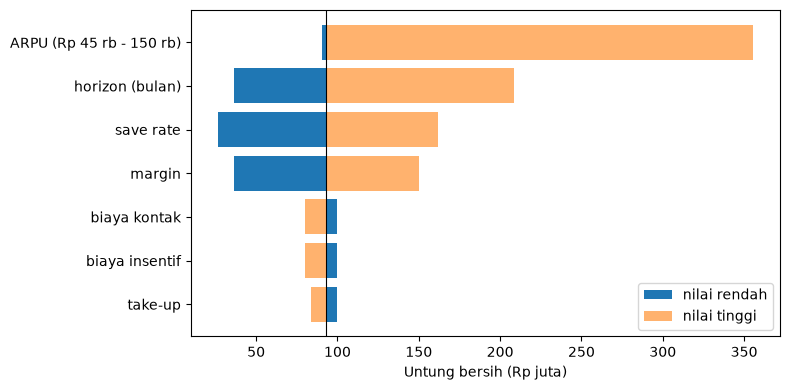

In [5]:
dasar, t = tornado(sc, P)
print(f"Dasar: Rp {dasar/1e6:.1f} juta"); print((t.set_index("parameter")[["rendah","tinggi"]]/1e6).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(t))[::-1]
ax.barh(y, (t["rendah"] - dasar)/1e6, left=dasar/1e6, label="nilai rendah")
ax.barh(y, (t["tinggi"] - dasar)/1e6, left=dasar/1e6, alpha=0.6, label="nilai tinggi")
ax.set_yticks(y); ax.set_yticklabels(t["parameter"]); ax.axvline(dasar/1e6, color="k", lw=0.8)
ax.set_xlabel("Untung bersih (Rp juta)"); ax.legend(); plt.tight_layout()
plt.savefig("../reports/figures/tornado.png", dpi=150); plt.show()

UNTUNG BERSIH (Rp juta)
       0.05  0.10  0.15  0.20   0.25   0.30   0.40
1250   17.4  40.5  63.8  87.1  110.8  134.4  181.8
2500   13.1  34.7  57.9  80.9  104.3  127.7  174.3
5000    6.9  26.2  47.4  69.5   92.7  115.8  161.8
7500    3.2  19.2  39.3  60.4   81.6  104.2  150.5
10000   0.9  13.9  32.2  52.5   73.1   94.7  139.0
15000   0.0   6.5  20.8  38.4   58.0   78.7  120.8

JUMLAH PELANGGAN LAYAK
       0.05  0.10  0.15  0.20  0.25  0.30  0.40
1250   3882  4829  5230  5543  5766  5921  6095
2500   3013  3882  4478  4829  5062  5230  5543
5000   1954  3013  3508  3882  4195  4478  4829
7500   1260  2470  3013  3376  3634  3882  4284
10000   525  1954  2626  3013  3292  3508  3882
15000     3  1260  1954  2470  2775  3013  3376


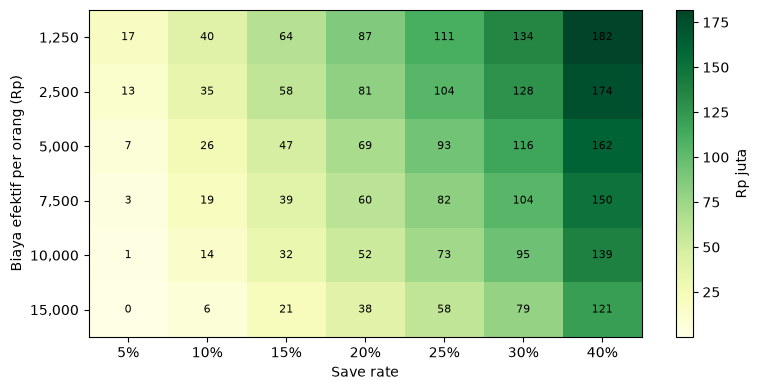

In [3]:
S = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
C = [1_250, 2_500, 5_000, 7_500, 10_000, 15_000]
u = peta(sc, P, S, C) / 1e6
n = peta(sc, P, S, C, kolom="n")

print("UNTUNG BERSIH (Rp juta)"); print(u.round(1))
print("\nJUMLAH PELANGGAN LAYAK"); print(n.astype(int))

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(u.values, aspect="auto", cmap="YlGn")
ax.set_xticks(range(len(S))); ax.set_xticklabels([f"{s:.0%}" for s in S])
ax.set_yticks(range(len(C))); ax.set_yticklabels([f"{c:,}" for c in C])
ax.set_xlabel("Save rate"); ax.set_ylabel("Biaya efektif per orang (Rp)")
for i in range(len(C)):
    for j in range(len(S)):
        ax.text(j, i, f"{u.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Rp juta"); plt.tight_layout()
plt.savefig("../reports/figures/heatmap_save_cost.png", dpi=150); plt.show()

In [4]:
k = ketahanan(sc, P, S)
print((k.set_index("save_rate_sebenarnya")/1e6).round(1))
ti = titik_impas(sc, P)
print({a: f"{v:.1%}" for a, v in ti.items()})
k.to_csv("../reports/sensitivity_robustness.csv", index=False)

                      hubungi_semua  daftar_asumsi_awal  daftar_dipilih_ulang
save_rate_sebenarnya                                                         
0.05                          -11.5                 1.8                   6.9
0.10                           12.2                24.5                  26.2
0.15                           35.9                47.2                  47.4
0.20                           59.7                69.9                  69.5
0.25                           83.4                92.7                  92.7
0.30                          107.1               115.4                 115.8
0.40                          154.5               160.8                 161.8
{'hubungi_semua': '7.4%', 'daftar_asumsi_awal': '4.6%'}
